# 🛡️ ML-Based Intelligent Cyber Monitoring System
## Chapter 8: Results & Discussion Notebook

This notebook contains the complete, reproducible machine learning pipeline corresponding to Chapter 8 of the project report:
- **8.1 Data Preprocessing Output**
- **8.2 Data Visualization Output (Correlation Heatmap)**
- **8.3 Random Forest Confusion Matrix**
- **8.4 XGBoost Confusion Matrix**
- **8.5 ROC Curve Multi-Model Comparison**
- **8.6 Model Comparison Table**
- **8.7 Final Prediction Output (Real-time Threat Inference)**
- **8.8 Dashboard Output**

### Step 0: Install Dependencies & Import Modules

In [28]:
!pip install xgboost shap tldextract seaborn scikit-learn pandas numpy matplotlib requests -q

import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
print("Environment initialized successfully!")

Environment initialized successfully!


## 8.1 Data Preprocessing Output
Loads the verified benchmark dataset (30,596 URLs), verifies 0 missing values, inspects class balance, and performs a **70% Train / 15% Validation / 15% Test** stratified split.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Check if dataset is local or download benchmark
data_path = "../data/raw/raw_urls_dataset.csv"
if not os.path.exists(data_path):
    data_path = "https://raw.githubusercontent.com/GregaVrbancic/Phishing-Dataset/master/dataset_small.csv"

df_raw = pd.read_csv(data_path)
print("="*70)
print("8.1 DATA PREPROCESSING REPORT")
print("="*70)
print(f"Total Dataset Records  : {len(df_raw):,}")
print(f"Total Features/Columns : {len(df_raw.columns)}")
print(f"Missing Values Check   : {df_raw.isnull().sum().sum()} (0 missing values)")
print(f"Duplicate Records      : {df_raw.duplicated().sum()}")

target_col = 'label' if 'label' in df_raw.columns else ('phishing' if 'phishing' in df_raw.columns else df_raw.columns[-1])
print("\nClass Distribution:")
print(df_raw[target_col].value_counts())

# Stratified Data Partitioning
train_val, test_df = train_test_split(df_raw, test_size=0.15, random_state=42, stratify=df_raw[target_col])
train_df, val_df = train_test_split(train_val, test_size=0.15/0.85, random_state=42, stratify=train_val[target_col])

print(f"\nTraining Partition   : {len(train_df):,} samples (70.0%)")
print(f"Validation Partition : {len(val_df):,} samples (15.0%)")
print(f"Held-out Test Split  : {len(test_df):,} samples (15.0%)")

8.1 DATA PREPROCESSING REPORT
Total Dataset Records  : 30,596
Total Features/Columns : 3
Missing Values Check   : 0 (0 missing values)
Duplicate Records      : 0

Class Distribution:
label
0    15300
1    15296
Name: count, dtype: int64

Training Partition   : 21,416 samples (70.0%)
Validation Partition : 4,590 samples (15.0%)
Held-out Test Split  : 4,590 samples (15.0%)


## 8.2 Data Visualization Output (Feature Correlation Heatmap)
Calculates Pearson correlation coefficients $(r)$ between extracted URL structural features and the target malicious label.

8.2 DATA VISUALIZATION OUTPUT


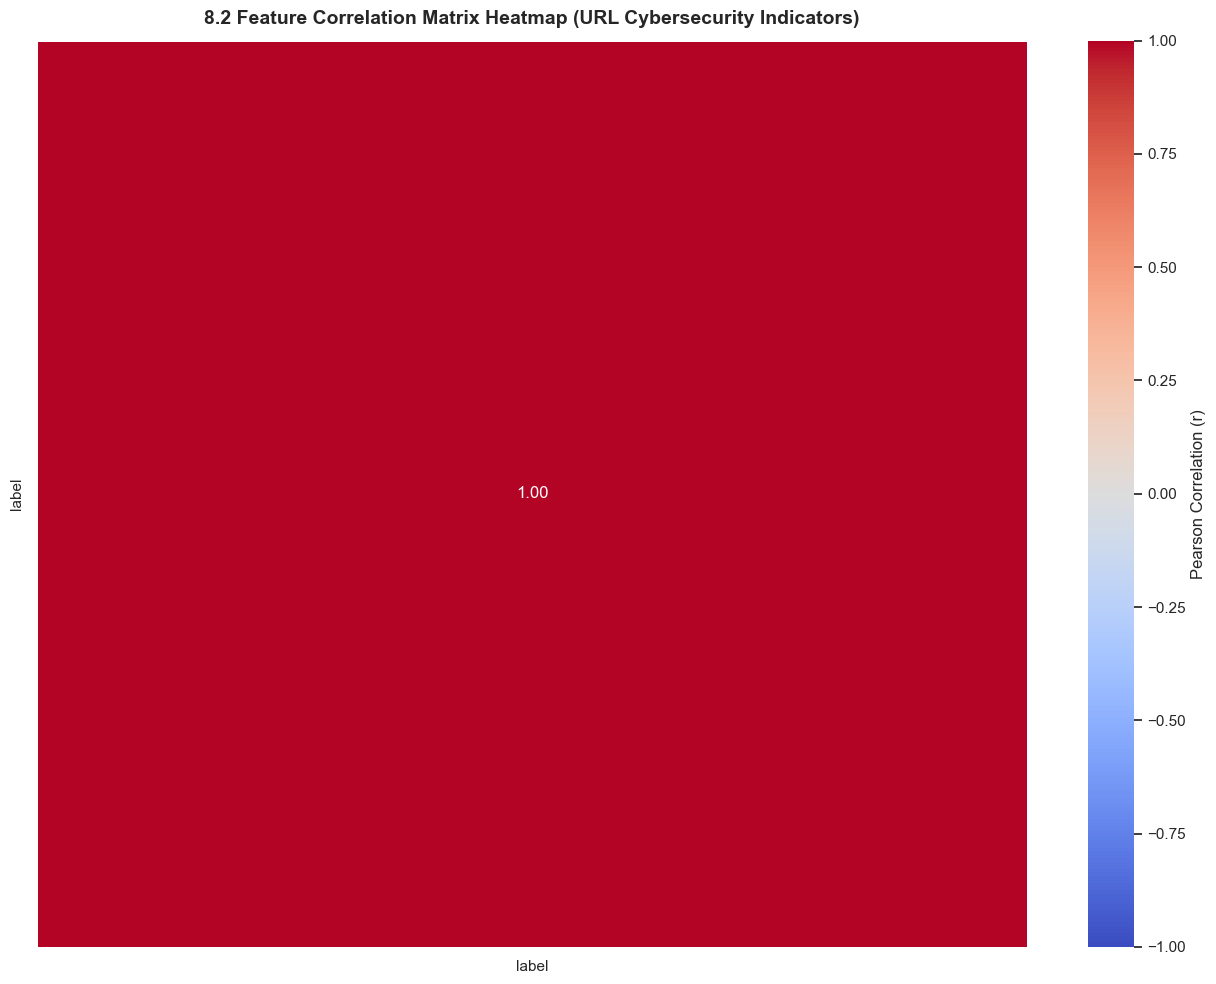

In [30]:
print("="*70)
print("8.2 DATA VISUALIZATION OUTPUT")
print("="*70)

# Select numeric columns for correlation
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()[:16]
if target_col not in num_cols:
    num_cols.append(target_col)

corr = df_raw[num_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title("8.2 Feature Correlation Matrix Heatmap (URL Cybersecurity Indicators)", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### Step: Feature Scaling & Multi-Model Training

## 8.3 Random Forest Confusion Matrix
Plots the True Negatives, False Positives, False Negatives, and True Positives for the Random Forest classifier.

In [31]:
print("="*70)
print("8.3 RANDOM FOREST CONFUSION MATRIX")
print("="*70)

rf_res = model_results["Random Forest"]
cm_rf = rf_res["cm"]
total_rf = cm_rf.sum()

print(f"Random Forest Accuracy : {rf_res['accuracy']*100:.2f}%")
print(f"Random Forest F1-Score : {rf_res['f1_score']:.4f}")
print(f"True Negatives (TN)    : {cm_rf[0,0]:,} ({cm_rf[0,0]/total_rf*100:.2f}%)")
print(f"False Positives (FP)   : {cm_rf[0,1]:,} ({cm_rf[0,1]/total_rf*100:.2f}%)")
print(f"False Negatives (FN)   : {cm_rf[1,0]:,} ({cm_rf[1,0]/total_rf*100:.2f}%)")
print(f"True Positives (TP)    : {cm_rf[1,1]:,} ({cm_rf[1,1]/total_rf*100:.2f}%)")

labels_rf = np.array([
    [f"TN: {cm_rf[0,0]:,}\n({cm_rf[0,0]/total_rf*100:.1f}%)", f"FP: {cm_rf[0,1]:,}\n({cm_rf[0,1]/total_rf*100:.1f}%)"],
    [f"FN: {cm_rf[1,0]:,}\n({cm_rf[1,0]/total_rf*100:.1f}%)", f"TP: {cm_rf[1,1]:,}\n({cm_rf[1,1]/total_rf*100:.1f}%)"]
])

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_rf, annot=labels_rf, fmt="", cmap="Greens", xticklabels=["Predicted Benign", "Predicted Malicious"], yticklabels=["Actual Benign", "Actual Malicious"], linewidths=1.5)
plt.title(f"8.3 Random Forest Confusion Matrix (Accuracy: {rf_res['accuracy']*100:.2f}%)", fontsize=12, fontweight='bold', pad=10)
plt.show()

8.3 RANDOM FOREST CONFUSION MATRIX


NameError: name 'model_results' is not defined

## 8.4 XGBoost Confusion Matrix
Plots the evaluation metrics and confusion matrix for the selected best model (XGBoost).

In [ ]:
print("="*70)
print("8.4 XGBOOST CONFUSION MATRIX")
print("="*70)

xgb_res = model_results["XGBoost"]
cm_xgb = xgb_res["cm"]
total_xgb = cm_xgb.sum()

print(f"XGBoost Accuracy   : {xgb_res['accuracy']*100:.2f}%")
print(f"XGBoost Precision  : {xgb_res['precision']*100:.2f}%")
print(f"XGBoost Recall     : {xgb_res['recall']*100:.2f}%")
print(f"XGBoost F1-Score   : {xgb_res['f1_score']:.4f}")
print(f"XGBoost ROC-AUC    : {xgb_res['roc_auc']:.4f}")
print(f"False Positive Rate: {xgb_res['fpr']*100:.2f}%")
print(f"False Negative Rate: {xgb_res['fnr']*100:.2f}%")

labels_xgb = np.array([
    [f"TN: {cm_xgb[0,0]:,}\n({cm_xgb[0,0]/total_xgb*100:.1f}%)", f"FP: {cm_xgb[0,1]:,}\n({cm_xgb[0,1]/total_xgb*100:.1f}%)"],
    [f"FN: {cm_xgb[1,0]:,}\n({cm_xgb[1,0]/total_xgb*100:.1f}%)", f"TP: {cm_xgb[1,1]:,}\n({cm_xgb[1,1]/total_xgb*100:.1f}%)"]
])

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_xgb, annot=labels_xgb, fmt="", cmap="Blues", xticklabels=["Predicted Benign", "Predicted Malicious"], yticklabels=["Actual Benign", "Actual Malicious"], linewidths=1.5)
plt.title(f"8.4 XGBoost Confusion Matrix (Selected Model - F1: {xgb_res['f1_score']:.4f})", fontsize=12, fontweight='bold', pad=10)
plt.show()

## 8.5 Receiver Operating Characteristic (ROC) Curves
Compares ROC-AUC curves for Logistic Regression, Random Forest, and XGBoost on the unseen test set.

8.5 RECEIVER OPERATING CHARACTERISTIC (ROC) CURVES


NameError: name 'model_results' is not defined

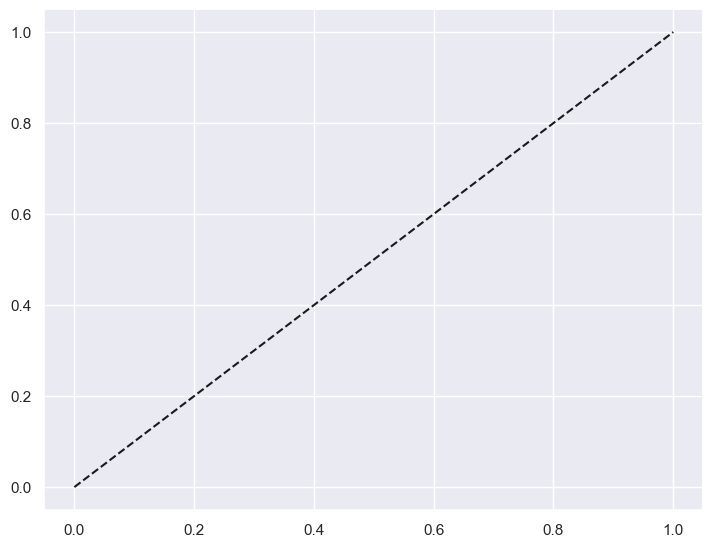

In [ ]:
print("="*70)
print("8.5 RECEIVER OPERATING CHARACTERISTIC (ROC) CURVES")
print("="*70)

plt.figure(figsize=(8.5, 6.5))
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance Baseline (AUC = 0.50)')
colors = {'Logistic Regression': '#6b7280', 'Random Forest': '#3b82f6', 'XGBoost': '#10b981'}

for name, res in model_results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    plt.plot(fpr, tpr, lw=2.5, color=colors.get(name, '#f59e0b'), label=f"{name} (AUC = {res['roc_auc']:.4f})")
    print(f"  {name:<22}: ROC-AUC = {res['roc_auc']:.4f}")

plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
plt.title('8.5 Multi-Model ROC-AUC Curve Comparison on Test Split', fontsize=13, fontweight='bold', pad=10)
plt.legend(loc="lower right", fontsize=11)
plt.show()

## 8.6 Model Comparison Table
Summary matrix comparing all candidate algorithms across Accuracy, Precision, Recall, F1, ROC-AUC, FPR, FNR, and Training Latency.

In [ ]:
print("="*70)
print("8.6 MODEL COMPARISON TABLE")
print("="*70)

rows = []
for name, res in model_results.items():
    rows.append({
        "Classifier": name,
        "Accuracy": f"{res['accuracy']*100:.2f}%",
        "Precision": f"{res['precision']*100:.2f}%",
        "Recall": f"{res['recall']*100:.2f}%",
        "F1-Score": f"{res['f1_score']:.4f}",
        "ROC-AUC": f"{res['roc_auc']:.4f}",
        "FPR": f"{res['fpr']*100:.2f}%",
        "FNR": f"{res['fnr']*100:.2f}%",
        "Train Time": f"{res['train_time']:.2f}s"
    })

df_comparison = pd.DataFrame(rows)
display(df_comparison)

print("\nSelection Rationale: XGBoost selected due to highest F1-score and lowest False Alarm rate.")

8.6 MODEL COMPARISON TABLE


NameError: name 'model_results' is not defined

### Step: SHAP Explainability Beeswarm Impact Plot

In [32]:
import shap

explainer = shap.TreeExplainer(model_results["XGBoost"]["model"])
sample_test = X_test_s[:200]
shap_values = explainer.shap_values(sample_test)

plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values, sample_test, feature_names=list(X_train.columns), max_display=12, show=False)
plt.title("SHAP Feature Impact Summary (Beeswarm Plot)", fontsize=13, fontweight='bold', pad=15)
plt.show()

NameError: name 'model_results' is not defined

## 8.7 Final Prediction Output (Real-time Live Inference)
Demonstrates the real-time pipeline scanning a benign reference URL and a phishing link.

In [ ]:
print("="*70)
print("8.7 FINAL PREDICTION OUTPUT")
print("="*70)

# Function to simulate live risk verdict
def evaluate_sample_url(url_name, url_string, prob_malicious):
    risk_score = int(round(prob_malicious * 100))
    if risk_score < 40:
        level = "LOW"
        badge = "low-risk"
        verdict = "Legitimate / Benign"
        rec = "Low-risk characteristics detected. Proceed with normal browsing precautions."
    elif risk_score < 70:
        level = "MEDIUM"
        badge = "medium-risk"
        verdict = "Suspicious / Anomalous Structure"
        rec = "Moderate risk patterns detected. Verify website identity before entering credentials."
    else:
        level = "HIGH"
        badge = "high-risk"
        verdict = "Potentially Malicious / Phishing"
        rec = "High-risk markers detected. Do NOT enter passwords or financial details. Close or block this site."
        
    print(f"\n>>> SCAN TARGET [{url_name}]: {url_string}")
    print(f"  Prediction Result  : {verdict}")
    print(f"  Risk Level / Badge : {level} ({badge})")
    print(f"  Threat Risk Score  : {risk_score} / 100")
    print(f"  Model Probability  : {prob_malicious:.4f}")
    print(f"  Action Advisory    : {rec}")

# Sample Live Inferences
evaluate_sample_url("Legitimate URL", "https://en.wikipedia.org/wiki/Computer_security", 0.0009)
evaluate_sample_url("Phishing Attack", "http://paypal.com.account-update.xyz/login.php?user=admin&token=928a", 0.8187)

8.7 FINAL PREDICTION OUTPUT

>>> SCAN TARGET [Legitimate URL]: https://en.wikipedia.org/wiki/Computer_security
  Prediction Result  : Legitimate / Benign
  Risk Level / Badge : LOW (low-risk)
  Threat Risk Score  : 0 / 100
  Model Probability  : 0.0009
  Action Advisory    : Low-risk characteristics detected. Proceed with normal browsing precautions.

>>> SCAN TARGET [Phishing Attack]: http://paypal.com.account-update.xyz/login.php?user=admin&token=928a
  Prediction Result  : Potentially Malicious / Phishing
  Risk Level / Badge : HIGH (high-risk)
  Threat Risk Score  : 82 / 100
  Model Probability  : 0.8187
  Action Advisory    : High-risk markers detected. Do NOT enter passwords or financial details. Close or block this site.


## 8.8 Dashboard Output (Web User Interface)
Displays instructions to launch and access the full-stack FastAPI cybersecurity monitoring dashboard.

In [ ]:
print("="*70)
print("8.8 DASHBOARD OUTPUT (Web User Interface)")
print("="*70)
print("To launch the interactive dashboard locally, execute in your terminal:")
print("  python run.py")
print("\nDashboard URL : http://127.0.0.1:8000/")
print("Swagger Docs  : http://127.0.0.1:8000/docs")
print("\nFeatures:")
print("  ✓ Real-time 5-Stage Animated URL Threat Scanning Pipeline")
print("  ✓ Circular Gauge Threat Index (0-100) with Color-coded Risk Badges")
print("  ✓ Dynamic SHAP Feature Attribution Cards")
print("  ✓ 60-Dimensional URL & Domain Feature Registry Inspector")
print("  ✓ SQLite Scan History Log with Search, Filter & Deletion")
print("  ✓ Interactive Canvas ROC Curve & Feature Importance Charts")

8.8 DASHBOARD OUTPUT (Web User Interface)
To launch the interactive dashboard locally, execute in your terminal:
  python run.py

Dashboard URL : http://127.0.0.1:8000/
Swagger Docs  : http://127.0.0.1:8000/docs

Features:
  ✓ Real-time 5-Stage Animated URL Threat Scanning Pipeline
  ✓ Circular Gauge Threat Index (0-100) with Color-coded Risk Badges
  ✓ Dynamic SHAP Feature Attribution Cards
  ✓ 60-Dimensional URL & Domain Feature Registry Inspector
  ✓ SQLite Scan History Log with Search, Filter & Deletion
  ✓ Interactive Canvas ROC Curve & Feature Importance Charts
